# Practical Task 1: Industry Classification from Business-Description Embeddings

In [11]:
import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

sns.set_theme(style="whitegrid")

# Loading Data

In [13]:
df = pd.read_pickle("data/df_train.pkl")
df_fin = pd.read_pickle("data/df_financials_train.pkl")
df_train, df_val = train_test_split(df, test_size=0.1, random_state=42)

def embeddings(series):
    # stored as strings "[0.01,-0.02,...]"; json.loads is a fast equivalent of ast.literal_eval
    return np.array([json.loads(s) for s in series], dtype=np.float32)

X_train = embeddings(df_train.business_description_embedding)
X_val = embeddings(df_val.business_description_embedding)
print(X_train.shape, X_val.shape)

(28535, 768) (3171, 768)


# Transforming Data (Label Encoding)

### Tasks:
- Use the scikit-learn label encoder to encode the industry names
- Check if all classes contained in the validation set are also in the training set# Label Encoding

In [14]:
le = LabelEncoder().fit(df_train.industry)
y_train = le.transform(df_train.industry)
y_val = le.transform(df_val.industry)
CLASSES, K = le.classes_, len(le.classes_)

print(f"{K} industries; classes in val but not in train: {set(df_val.industry) - set(CLASSES) or 'none'}")

25 industries; classes in val but not in train: none


# Visualize the Data

### Tasks:
- Are certain classes over- or under represented? Either produce a table or a plot to show this.
- Inspect whether there is signal in the business description embeddings:
    - Perform a PCA to project data into 2 dimensions
    - Plot projected data in Scatterplot and color based on classes
    - Provide a description of what you see and judge whether there is signal in the data that allows industry classification

Important: Ensure that your plots have proper axis descriptions and titles. Style the plots so that differences in class distributions are visible (e.g. scatter size, transparency, color, etc.)

### Class distribution

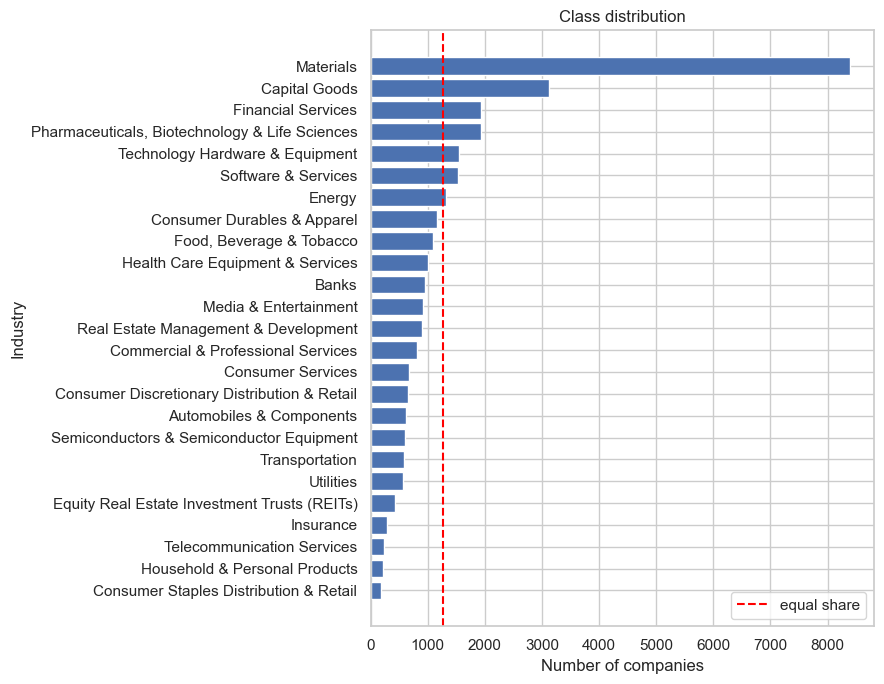

largest / smallest class: 8394 / 178 = 47x


In [15]:
counts = df.industry.value_counts()
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(counts.index[::-1], counts.values[::-1])
ax.axvline(counts.mean(), color="red", ls="--", label="equal share")
ax.set(xlabel="Number of companies", ylabel="Industry", title="Class distribution")
ax.legend(); plt.tight_layout(); plt.show()
print(f"largest / smallest class: {counts.max()} / {counts.min()} = {counts.max() / counts.min():.0f}x")

**Findings:** The classes are strongly imbalanced. *Materials* alone is ~26% of all companies, while the
smallest industries (e.g. Consumer Staples Distribution & Retail, Household & Personal Products) are below 1%.
Accuracy and weighted F1 are therefore dominated by the large classes, so we also report macro F1.

### PCA

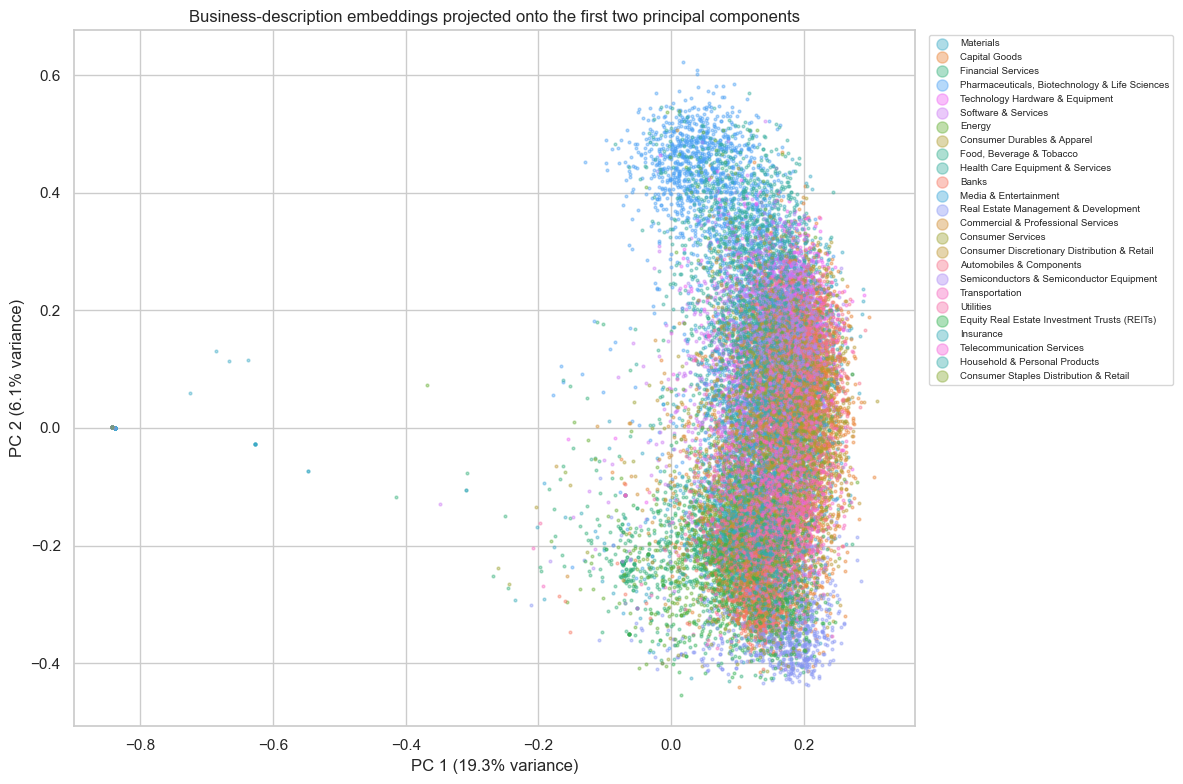

In [ ]:
# Check if the plot should be centred, remove outliers.

pca = PCA(n_components=2).fit(X_train)
Z = pca.transform(X_train)
ev = 100 * pca.explained_variance_ratio_

palette = dict(zip(CLASSES, sns.color_palette("husl", K)))
fig, ax = plt.subplots(figsize=(12, 8))
for ind in counts.index:  # large classes first, so small classes are drawn on top
    m = df_train.industry.values == ind
    ax.scatter(Z[m, 0], Z[m, 1], s=4, alpha=0.4, color=palette[ind], label=ind)
ax.set(xlabel=f"PC 1 ({ev[0]:.1f}% variance)", ylabel=f"PC 2 ({ev[1]:.1f}% variance)",
       title="Business-description embeddings projected onto the first two principal components")
ax.legend(markerscale=4, fontsize=7, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.show()

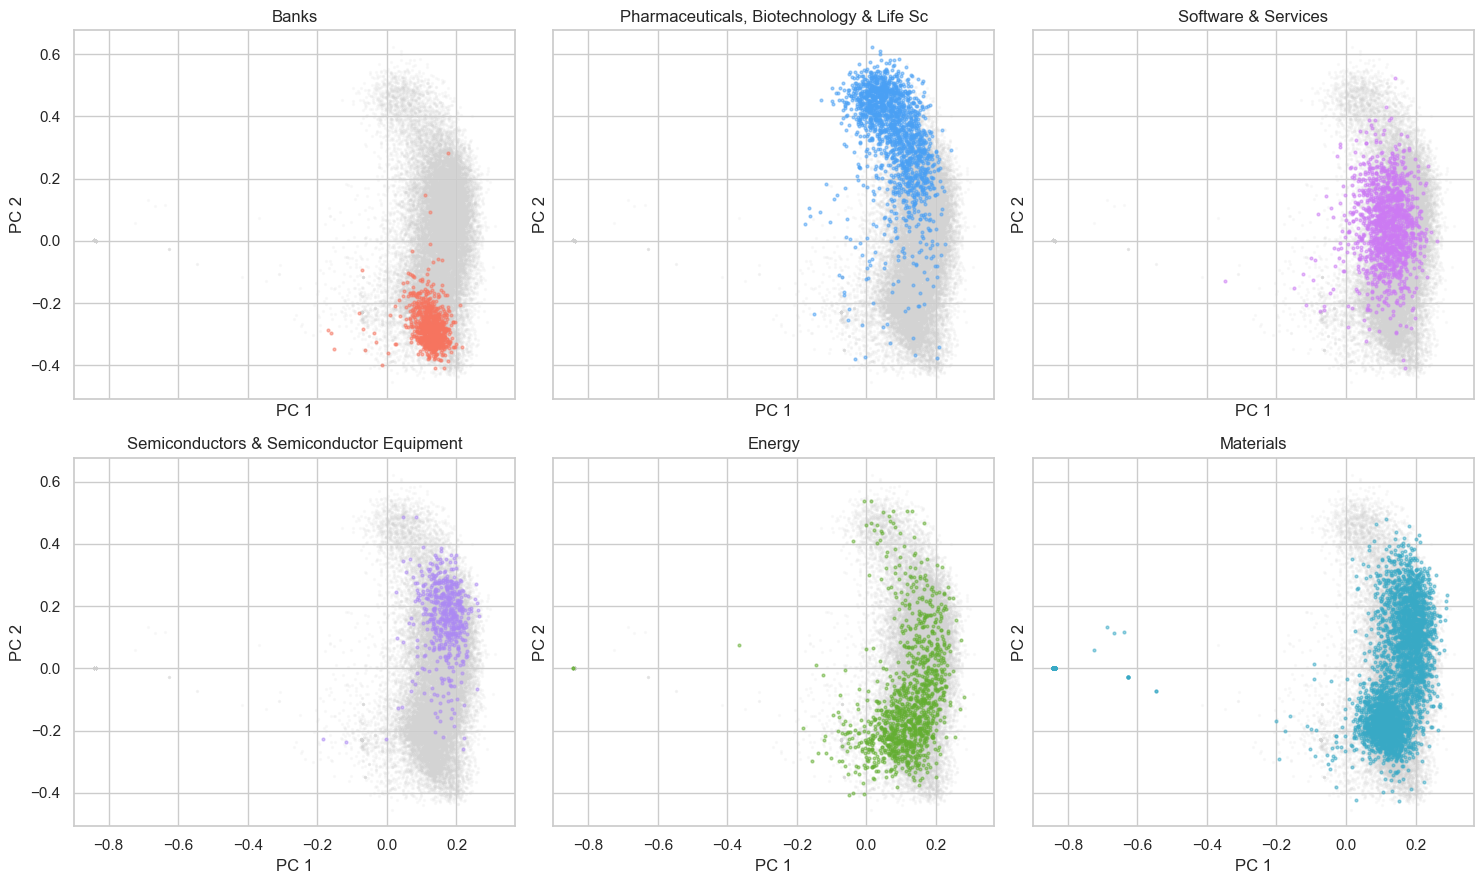

In [17]:
# 25 colours overlap, so highlight a few industries against all others (grey)
show = ["Banks", "Pharmaceuticals, Biotechnology & Life Sciences", "Software & Services",
        "Semiconductors & Semiconductor Equipment", "Energy", "Materials"]
fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharex=True, sharey=True)
for ax, ind in zip(axes.flat, show):
    m = df_train.industry.values == ind
    ax.scatter(Z[~m, 0], Z[~m, 1], s=2, alpha=0.1, color="lightgrey")
    ax.scatter(Z[m, 0], Z[m, 1], s=4, alpha=0.5, color=palette[ind])
    ax.set(title=ind[:40], xlabel="PC 1", ylabel="PC 2")
plt.tight_layout(); plt.show()

removed 4189 shared-embedding + 122 distant points; 24,224 remain


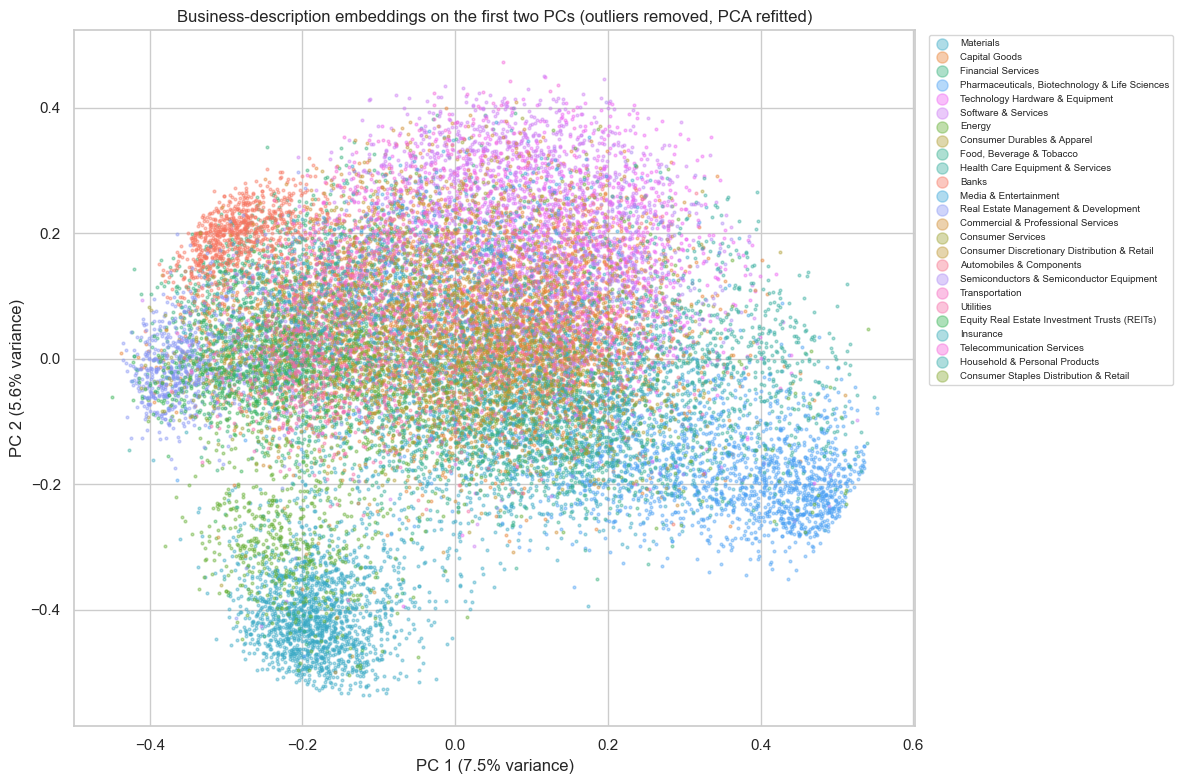

In [31]:
# PCA without outliers
# 1) drop the identical "empty description" embeddings
shared = df_train.business_description_embedding.duplicated(keep=False).values
X_c, ind_c = X_train[~shared], df_train.industry.values[~shared]

# 2) refit PCA on the clean data, then trim points far from the bulk (robust, median-based)
pca_c = PCA(n_components=2).fit(X_c)
Z_c = pca_c.transform(X_c)
dist = np.linalg.norm(Z_c - np.median(Z_c, axis=0), axis=1)
inlier = dist <= np.quantile(dist, 0.995)          # drop the 0.5% most distant points
Z_c, ind_c = Z_c[inlier], ind_c[inlier]
ev_c = 100 * pca_c.explained_variance_ratio_
print(f"removed {shared.sum()} shared-embedding + {(~inlier).sum()} distant points; {len(Z_c):,} remain")

fig, ax = plt.subplots(figsize=(12, 8))
for ind in counts.index:                            # large classes first, small classes on top
    m = ind_c == ind
    ax.scatter(Z_c[m, 0], Z_c[m, 1], s=4, alpha=0.4, color=palette[ind], label=ind)
ax.set(xlabel=f"PC 1 ({ev_c[0]:.1f}% variance)", ylabel=f"PC 2 ({ev_c[1]:.1f}% variance)",
       title="Business-description embeddings on the first two PCs (outliers removed, PCA refitted)")
ax.legend(markerscale=4, fontsize=7, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.show()

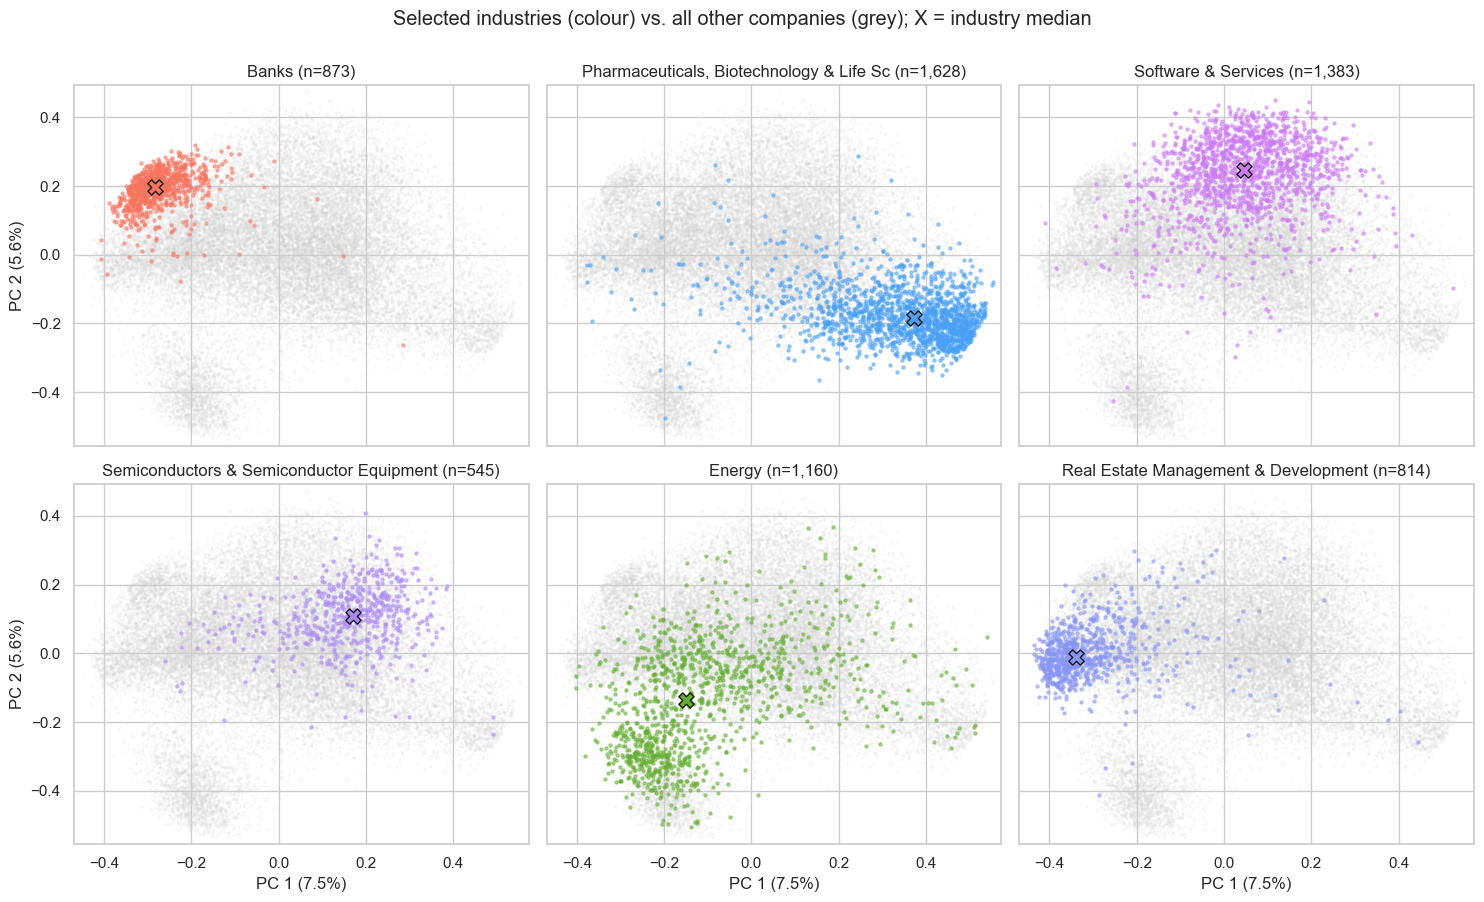

In [32]:
# Highlight a few industries against all others (uses the cleaned PCA from the previous cell)
show = ["Banks",
        "Pharmaceuticals, Biotechnology & Life Sciences",
        "Software & Services",
        "Semiconductors & Semiconductor Equipment",
        "Energy",
        "Real Estate Management & Development"]      # edit this list freely

xlim = (Z_c[:, 0].min() - 0.02, Z_c[:, 0].max() + 0.02)
ylim = (Z_c[:, 1].min() - 0.02, Z_c[:, 1].max() + 0.02)

fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharex=True, sharey=True)
for ax, ind in zip(axes.flat, show):
    m = ind_c == ind
    ax.scatter(Z_c[~m, 0], Z_c[~m, 1], s=2, alpha=0.1, color="lightgrey", rasterized=True)
    ax.scatter(Z_c[m, 0], Z_c[m, 1], s=5, alpha=0.5, color=palette[ind], rasterized=True)
    cx, cy = np.median(Z_c[m], axis=0)               # industry median, to compare across panels
    ax.scatter(cx, cy, marker="X", s=120, color=palette[ind], edgecolor="k", zorder=3)
    ax.set(title=f"{ind[:40]} (n={m.sum():,})", xlim=xlim, ylim=ylim)
for ax in axes[-1]:
    ax.set_xlabel(f"PC 1 ({ev_c[0]:.1f}%)")
for ax in axes[:, 0]:
    ax.set_ylabel(f"PC 2 ({ev_c[1]:.1f}%)")
fig.suptitle("Selected industries (colour) vs. all other companies (grey); X = industry median", y=1.00)
plt.tight_layout(); plt.show()

**Findings:** The first two components explain only ~25% of the variance, so the 2-D view is a rough projection
of a 768-dimensional space. Still, industries clearly occupy different regions: PC 2 separates life-science
companies (Pharma, top) from financial/real-estate companies (Banks, bottom), with technology in between.
Related industries overlap (e.g. Semiconductors and Technology Hardware). The isolated point at PC 1 ≈ −0.85 is
one embedding shared by ~4,400 companies (probably an empty description), almost all of them *Materials*.
**There is clear signal for industry classification**, but neighbouring industries will be confused.

# Fitting and Comparing Classifier Models

### Tasks:
- Split the data into train and validation data
- Encode the industry labels using LabelEncoder (scikit-learn)
- Fit a LogisticRegression and a kNN-classifier
- Compare the model performance of both models:
    - Compute Accuracy and F1 score
        - Interpret the scores: Explain how they are computed and judge if your model performs well
        - Analyze the classification errors: 
            - Do the errors correlate with how well classes are represented?
            - Which industries does the model identify well and which seem to be similar?
    - Plot a confusion matrix for both models (combine scikit-learn confusion matrix and seaborn heatmap plot)
    - Do both models misclassify the same examples?

Import: Use proper axis labels for the plots! 

In [18]:
lr = LogisticRegression(C=4, max_iter=2000).fit(X_train, y_train)
knn = KNeighborsClassifier(n_neighbors=15, metric="cosine", weights="distance").fit(X_train, y_train)
pred_lr, pred_knn = lr.predict(X_val), knn.predict(X_val)

pd.DataFrame({
    name: {"accuracy": accuracy_score(y_val, p),
           "F1 weighted": f1_score(y_val, p, average="weighted"),
           "F1 macro": f1_score(y_val, p, average="macro")}
    for name, p in [("Logistic Regression", pred_lr), ("kNN (k=15)", pred_knn)]
}).T.round(3)

,accuracy,F1 weighted,F1 macro
Logistic Regression,0.776,0.772,0.706
kNN (k=15),0.775,0.770,0.699


**Interpretation:** *Accuracy* is the share of correctly classified companies. *F1* per class is the harmonic
mean of precision (how many predicted *k* really are *k*) and recall (how many true *k* were found);
*weighted F1* averages it by class size, *macro F1* gives every class equal weight.
Both models reach ~78% accuracy on 25 classes (majority-class baseline: ~25%), which is good given that
industry boundaries are fuzzy. Macro F1 (~0.70) is lower than weighted F1, so small classes are harder.

### Errors vs. class size

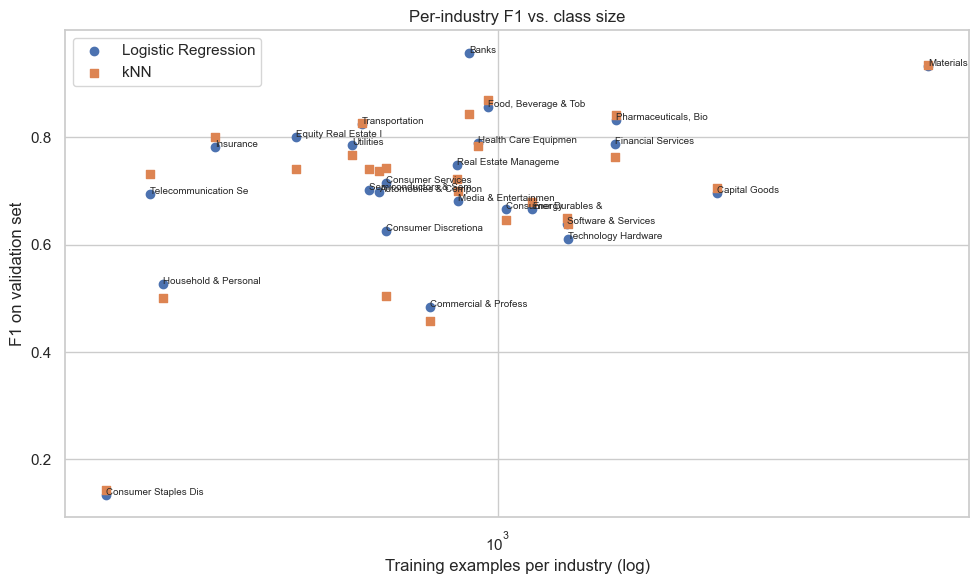

Spearman correlation class size vs. F1 (LR): rho = 0.22, p = 0.28


In [19]:
f1_lr = f1_score(y_val, pred_lr, average=None)
f1_knn = f1_score(y_val, pred_knn, average=None)
support = np.bincount(y_train, minlength=K)

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(support, f1_lr, label="Logistic Regression")
ax.scatter(support, f1_knn, marker="s", label="kNN")
for i, name in enumerate(CLASSES):
    ax.annotate(name[:20], (support[i], f1_lr[i]), fontsize=7)
ax.set(xscale="log", xlabel="Training examples per industry (log)", ylabel="F1 on validation set",
       title="Per-industry F1 vs. class size")
ax.legend(); plt.tight_layout(); plt.show()

rho, p = stats.spearmanr(support, f1_lr)
print(f"Spearman correlation class size vs. F1 (LR): rho = {rho:.2f}, p = {p:.2f}")

### Confusion matrices

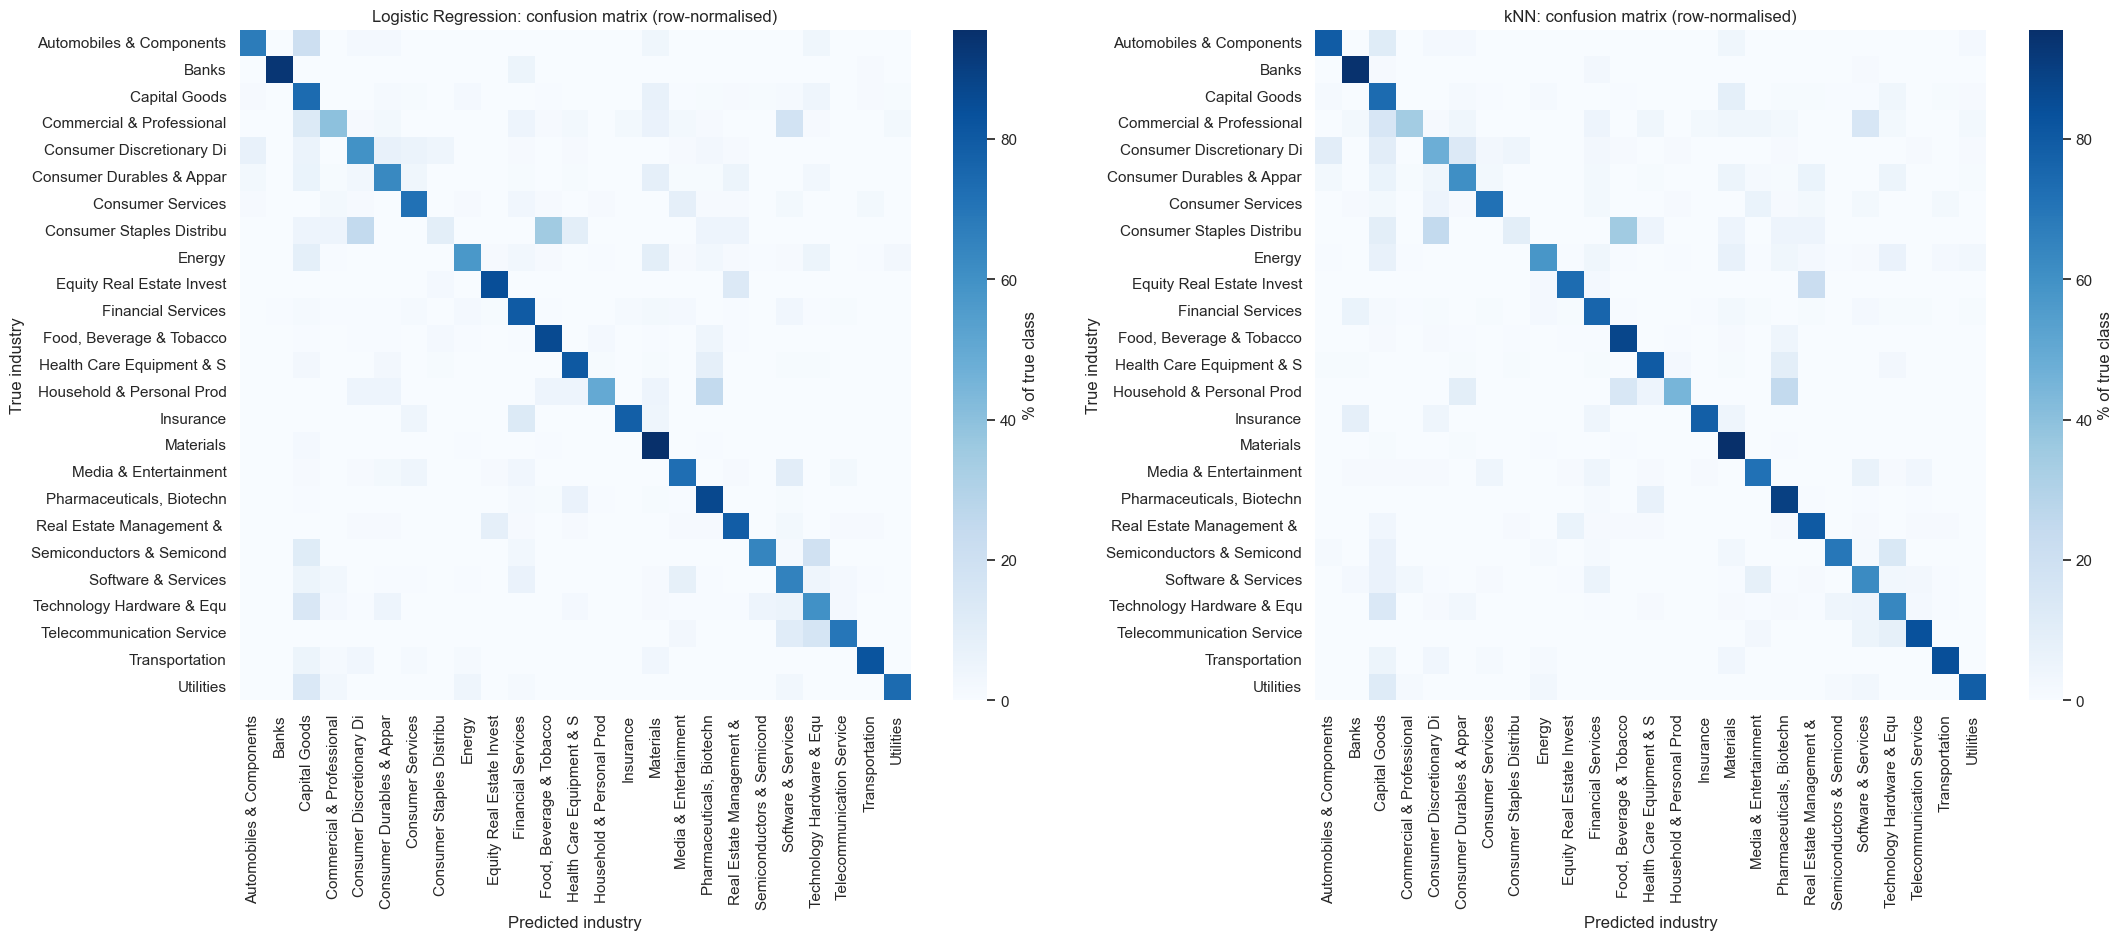

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(22, 9))
for ax, (name, p) in zip(axes, [("Logistic Regression", pred_lr), ("kNN", pred_knn)]):
    cm = confusion_matrix(y_val, p, normalize="true")
    sns.heatmap(100 * cm, ax=ax, cmap="Blues", square=True, cbar_kws={"label": "% of true class"},
                xticklabels=[c[:25] for c in CLASSES], yticklabels=[c[:25] for c in CLASSES])
    ax.set(xlabel="Predicted industry", ylabel="True industry", title=f"{name}: confusion matrix (row-normalised)")
plt.tight_layout(); plt.show()

In [21]:
# largest off-diagonal entries = most similar industries
cm = confusion_matrix(y_val, pred_lr)
np.fill_diagonal(cm, 0)
i, j = np.unravel_index(np.argsort(cm, axis=None)[::-1][:8], cm.shape)
pd.DataFrame({"true": CLASSES[i], "predicted (LR)": CLASSES[j], "count": cm[i, j]})

,true,predicted (LR),count
0,Technology Hardware & Equipment,Capital Goods,23
1,Capital Goods,Materials,23
2,Materials,Capital Goods,15
3,Energy,Materials,15
4,Commercial & Professional Services,Software & Services,14
5,Capital Goods,Technology Hardware & Equipment,14
6,Energy,Capital Goods,14
7,Software & Services,Media & Entertainment,13


### Which industries are similar? (PCA)
Each industry is drawn at the mean PCA position of its companies (marker area grows with the number of companies).
Red lines connect the 10 industry pairs that Logistic Regression confuses most often (line width ~ number of
confusions). Companies sharing the identical "empty description" embedding are excluded from the centres,
otherwise they would pull *Materials* far to the left.

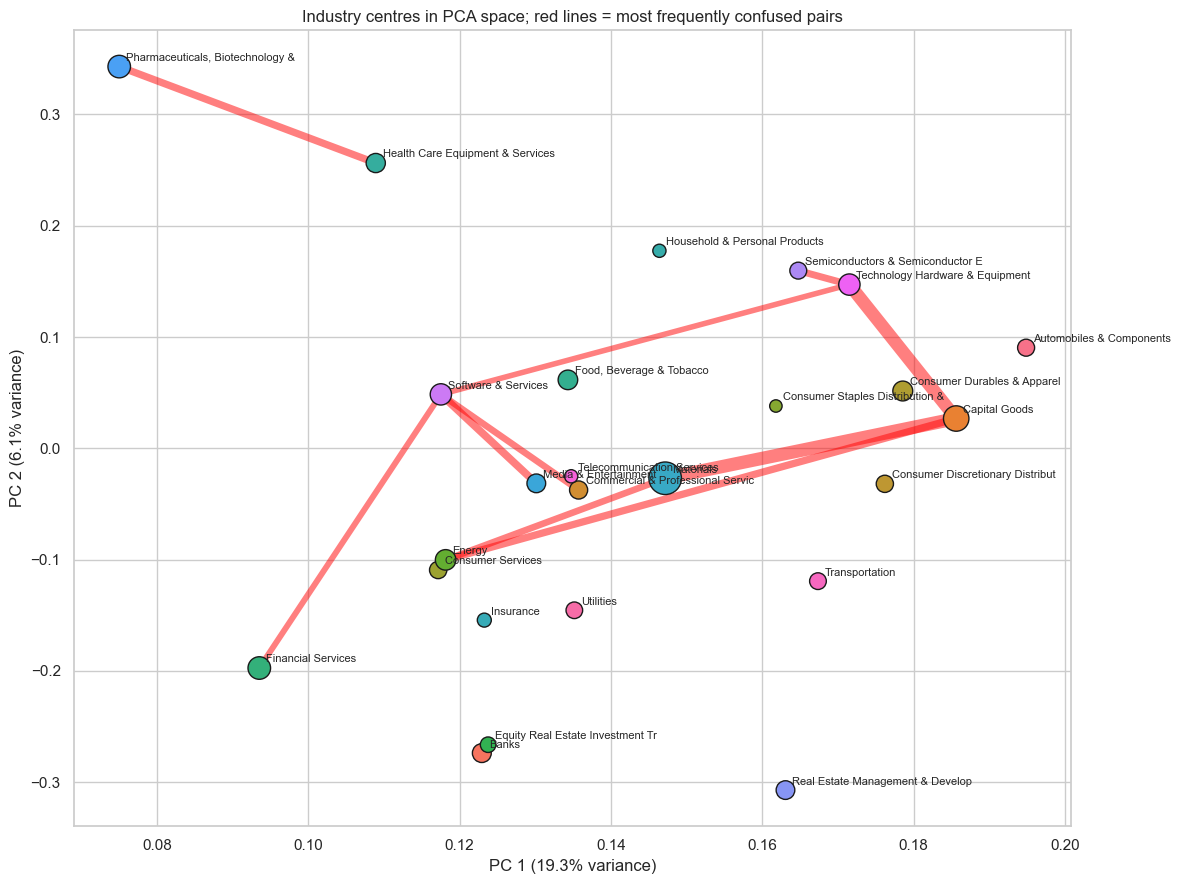

In [ ]:
# This part should be moved before confusion matrix. Check if the graph is actually accurate based on the lines and positions of the industries.
#honestly we could just remove this


shared = df_train.business_description_embedding.duplicated(keep=False).values
centres = pd.DataFrame(Z[~shared], columns=["PC1", "PC2"]).groupby(df_train.industry.values[~shared]).mean()

conf = confusion_matrix(y_val, pred_lr)
pairs = np.triu(conf + conf.T, 1)                     # confusions in both directions
a, b = np.unravel_index(np.argsort(pairs, axis=None)[::-1][:10], pairs.shape)

fig, ax = plt.subplots(figsize=(12, 9))
for p, q in zip(a, b):
    P, Q = centres.loc[CLASSES[p]], centres.loc[CLASSES[q]]
    ax.plot([P.PC1, Q.PC1], [P.PC2, Q.PC2], color="red", alpha=0.5, lw=pairs[p, q] / 4, zorder=1)
ax.scatter(centres.PC1, centres.PC2, s=6 * np.sqrt(counts[centres.index]), c=[palette[c] for c in centres.index],
           edgecolor="k", zorder=2)
for name, r in centres.iterrows():
    ax.annotate(name[:32], (r.PC1, r.PC2), fontsize=8, xytext=(5, 4), textcoords="offset points")
ax.set(xlabel=f"PC 1 ({ev[0]:.1f}% variance)", ylabel=f"PC 2 ({ev[1]:.1f}% variance)",
       title="Industry centres in PCA space; red lines = most frequently confused pairs")
plt.tight_layout(); plt.show()

### Do both models misclassify the same examples?

In [23]:
# Check this, whether its for a specific industry or all. (Is it based on the validation test)

lr_ok, knn_ok = pred_lr == y_val, pred_knn == y_val
display(pd.crosstab(np.where(lr_ok, "LR correct", "LR wrong"), np.where(knn_ok, "kNN correct", "kNN wrong")))

b, c = (lr_ok & ~knn_ok).sum(), (~lr_ok & knn_ok).sum()
print(f"McNemar test (H0: equal error rates): p = {stats.binomtest(b, b + c).pvalue:.2f}")
print(f"accuracy if at least one model is correct: {np.mean(lr_ok | knn_ok):.3f}")

col_0,kNN correct,kNN wrong
row_0,,
LR correct,2282,178
LR wrong,177,534


McNemar test (H0: equal error rates): p = 1.00
accuracy if at least one model is correct: 0.832


**Error analysis:**
- Class size correlates only weakly with F1 (Spearman ρ ≈ 0.2, not significant). How *distinctive* an
  industry's description is matters more: Banks, Materials, Food/Beverage and Pharma are recognised well
  (F1 > 0.83), while broad groups such as Capital Goods, Software and Technology Hardware are harder (~0.65–0.70).
- Similar industries (close together in the PCA centre plot and joined by red lines): Semiconductors ↔ Technology Hardware, many manufacturers → Capital Goods, Energy ↔ Materials,
  Commercial & Professional Services → Software, REITs ↔ Real Estate Management, Consumer Staples Retail → Food.
- Both models mostly fail on the same companies (~530 shared errors out of ~710 each). Neither is significantly
  better (McNemar p ≈ 0.8). But each fixes ~180 errors of the other, so combining them should help.

# Optional: Confidence Weighted Prediction

## Deliverables:

- Provide a notebook with the implementation and training of an industry classifier model
- The model shall output the industry classification and its confidence as a tuple of vectors $(\hat{y}_{pred}, \hat{y}_{confidence})$
- The confidence score must be between 0 and 1, $\hat{y}_{confidence} [i] \in [0,1]$
- Your model will be evaluated on a private test set
- Designing the confidence score is your task. You may use p-values, a voting mechanism of multiple models, or other techniques
- Another option is to add more features, e.g. financial data, to X

## Scoring

Your submission is scored with the function `confidence_score` below:

$$\text{score} = F_1^{\text{weighted}}(y, \hat{y}_{pred}) \cdot \left(1 - \text{Brier}\right), \qquad \text{Brier} = \frac{1}{n}\sum_{i=1}^{n} \left(\hat{y}_{confidence}[i] - \mathbb{1}[\hat{y}_{pred}[i] = y_i]\right)^2$$

- **Weighted F1** measures how good your predicted industries are (the confidence does not enter here).
- **Brier score** measures how good your confidence is: $\hat{y}_{confidence}[i]$ should be the probability that prediction $i$ is correct.
- The Brier term is smallest when your confidence is *calibrated*: among all predictions with confidence 0.8, about 80% should be correct.
- Always reporting confidence 1.0 does not pay off (every wrong prediction costs the maximum penalty), and neither does reporting very low confidence everywhere.

In [24]:
def confidence_score(y_true, y_pred, confidence):
    y_true, y_pred, confidence = np.asarray(y_true), np.asarray(y_pred), np.asarray(confidence, dtype=float)
    assert np.all((confidence >= 0) & (confidence <= 1))
    f1 = f1_score(y_true, y_pred, average="weighted")
    brier = np.mean((confidence - (y_true == y_pred)) ** 2)
    return f1 * (1 - brier)

print(f"baseline (LR, max probability): {confidence_score(y_val, pred_lr, lr.predict_proba(X_val).max(1)):.4f}")

baseline (LR, max probability): 0.6658


### Financial data: outliers, missing values and distributions across industries
- Ratios with a zero denominator are ±∞ → set to NaN, but keep a flag (zero revenue is informative,
  e.g. exploration miners, pre-revenue biotechs).
- Extreme outliers → winsorise at the 1% / 99% quantiles.
- Missing values (EBITDA margin is missing for ~65%) → kept as NaN, which gradient boosting handles natively.
- Some ids have two rows (one empty) → take the first non-missing value per id.

In [25]:
FIN = ["net_profit_margin", "ebitda_margin", "asset_turnover"]

def clean_financials(fin, clip=None):
    g = fin.copy()
    for c in FIN:
        g[c + "_inf"] = np.sign(g[c]).where(np.isinf(g[c]), 0)   # +1 / -1 / 0
        g[c] = g[c].replace([np.inf, -np.inf], np.nan)
    g = g.groupby("id").first()
    clip = clip or {c: g[c].quantile([0.01, 0.99]).tolist() for c in FIN}
    for c in FIN:
        g[c] = g[c].clip(*clip[c])
    return g, clip

fin_clean, _ = clean_financials(df_fin)
dfm = df[["id", "industry"]].join(fin_clean, on="id", how="inner")
print(f"{len(dfm):,} of {len(df):,} companies have financial data")

29,400 of 31,706 companies have financial data


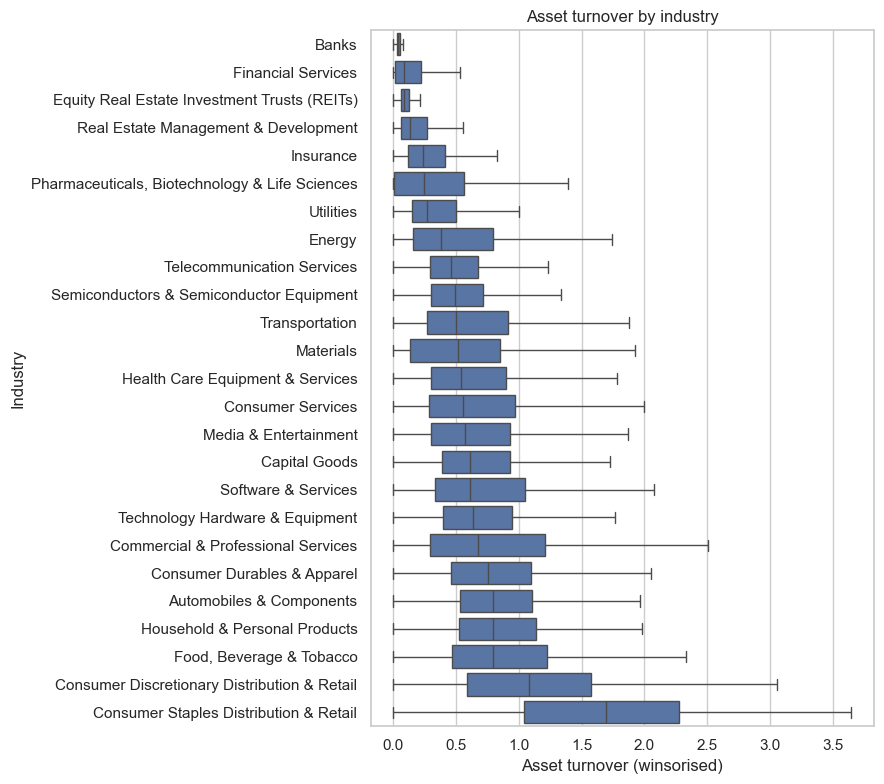

net_profit_margin  H =    2896   p = 0.0e+00
ebitda_margin      H =    1818   p = 0.0e+00
asset_turnover     H =    6096   p = 0.0e+00


In [26]:
fig, ax = plt.subplots(figsize=(9, 8))
order = dfm.groupby("industry").asset_turnover.median().sort_values().index
sns.boxplot(data=dfm, y="industry", x="asset_turnover", order=order, showfliers=False, ax=ax)
ax.set(xlabel="Asset turnover (winsorised)", ylabel="Industry", title="Asset turnover by industry")
plt.tight_layout(); plt.show()

# Kruskal-Wallis: H0 = the ratio has the same distribution in all industries (rank-based, robust to outliers)
for c in FIN:
    H, p = stats.kruskal(*[g.dropna() for _, g in dfm.groupby("industry")[c]])
    print(f"{c:18s} H = {H:7.0f}   p = {p:.1e}")

**Findings:** All three ratios differ significantly between industries (p ≈ 0), and the differences make economic
sense (banks and REITs have very low asset turnover, retailers very high; biotechs have negative margins).
But the distributions overlap heavily, so financial data is only a weak, complementary signal.

### Ensemble with calibrated confidence and p-values
1. **Embedding models:** average of Logistic Regression and kNN probabilities.
2. **Financial model:** gradient boosting on the cleaned ratios + country. It is weak, so it only *corrects* the
   embedding prediction: $\log P = \log P_{emb} + \alpha(\log P_{fin} - \log P_{prior})$.
3. **Confidence:** the maximum ensemble probability, calibrated with isotonic regression on out-of-fold predictions.
4. **p-values (conformal prediction):** for industry $k$, $p_k$ = share of training companies whose true-class
   probability was as low as or lower than $P(k \mid x)$. Industries with $p_k > 0.1$ form a 90% prediction set.
   A prediction is **flagged for human review** if this set contains more than one industry or the confidence is below 0.5.

In [27]:
W_LR, ALPHA = 0.6, 0.25

def fin_features(ids, fin_clean, countries):
    F = fin_clean.reindex(ids)
    has_fin = F.drop(columns="country_code").notna().any(axis=1).to_numpy()
    country = pd.Categorical(F.pop("country_code"), categories=countries).codes.astype(float)
    F["country"] = np.where(country < 0, np.nan, country)   # last column, treated as categorical
    return F.to_numpy(float), has_fin

def expand(P, classes):
    """put probabilities of the classes seen by a model into a full K-column matrix"""
    out = np.full((len(P), K), 1e-6)
    out[:, classes] = P
    return out / out.sum(1, keepdims=True)

def combine(P_lr, P_knn, P_fin, prior):
    L = np.log(W_LR * P_lr + (1 - W_LR) * P_knn + 1e-6) + ALPHA * (np.log(P_fin + 1e-6) - np.log(prior))
    P = np.exp(L - L.max(1, keepdims=True))
    return P / P.sum(1, keepdims=True)

def fit_models(X, y, F, has_fin):
    fin_model = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, max_leaf_nodes=15,
                                               categorical_features=[F.shape[1] - 1], random_state=0)
    return {"lr": LogisticRegression(C=4, max_iter=2000).fit(X, y),
            "knn": KNeighborsClassifier(15, metric="cosine", weights="distance").fit(X, y),
            "fin": fin_model.fit(F[has_fin], y[has_fin])}

def model_proba(models, X, F, has_fin, prior):
    P_fin = np.tile(prior, (len(X), 1))
    if has_fin.any():
        P_fin[has_fin] = expand(models["fin"].predict_proba(F[has_fin]), models["fin"].classes_)
    return combine(expand(models["lr"].predict_proba(X), models["lr"].classes_),
                   expand(models["knn"].predict_proba(X), models["knn"].classes_), P_fin, prior)

def fit_ensemble(df, df_fin):
    X = embeddings(df.business_description_embedding)
    y = le.transform(df.industry)
    fin_clean, clip = clean_financials(df_fin)
    countries = sorted(fin_clean.country_code.dropna().unique())
    F, has_fin = fin_features(df.id.values, fin_clean, countries)
    prior = np.bincount(y, minlength=K) / len(y)

    # out-of-fold predictions -> confidence calibration and conformal p-values
    P_oof = np.zeros((len(y), K))
    for tr, te in StratifiedKFold(5, shuffle=True, random_state=0).split(X, y):
        P_oof[te] = model_proba(fit_models(X[tr], y[tr], F[tr], has_fin[tr]), X[te], F[te], has_fin[te], prior)
    correct = (P_oof.argmax(1) == y).astype(float)

    return {"models": fit_models(X, y, F, has_fin), "clip": clip, "countries": countries, "prior": prior,
            "calibrator": IsotonicRegression(y_min=0, y_max=1, out_of_bounds="clip").fit(P_oof.max(1), correct),
            "scores": np.sort(1 - P_oof[np.arange(len(y)), y])}

def predict(model, df, df_fin):
    """returns (y_pred, y_confidence, p_values)"""
    X = embeddings(df.business_description_embedding)
    F, has_fin = fin_features(df.id.values, clean_financials(df_fin, model["clip"])[0], model["countries"])
    P = model_proba(model["models"], X, F, has_fin, model["prior"])
    s = model["scores"]
    p_values = (1 + len(s) - np.searchsorted(s, 1 - P)) / (len(s) + 1)
    return le.inverse_transform(P.argmax(1)), model["calibrator"].predict(P.max(1)), p_values

In [28]:
#How to improve the model?

t0 = time.time()
model = fit_ensemble(df_train, df_fin)
print(f"training time: {time.time() - t0:.0f}s")

y_pred, conf, p_values = predict(model, df_val, df_fin)
y_true = df_val.industry.values
correct = y_pred == y_true
print(f"accuracy {correct.mean():.4f} | F1 weighted {f1_score(y_true, y_pred, average='weighted'):.4f} | "
      f"Brier {np.mean((conf - correct) ** 2):.4f} | score {confidence_score(y_true, y_pred, conf):.4f}")

training time: 115s
accuracy 0.7878 | F1 weighted 0.7839 | Brier 0.1295 | score 0.6824


### Confidence vs. accuracy and human review

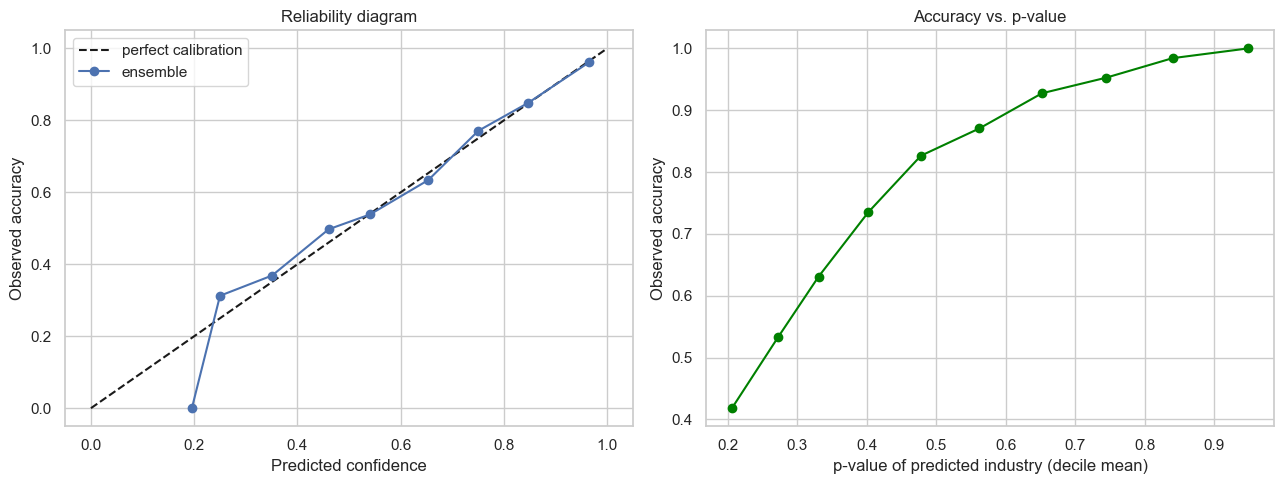

90% prediction sets: coverage 0.902, mean size 1.54


,share,accuracy
automatic,0.588,0.928
flagged for review,0.412,0.588


In [29]:
set_size = (p_values > 0.1).sum(1)
review = (set_size > 1) | (conf < 0.5)
p_pred = p_values.max(1)   # p-value of the predicted industry

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
bins = pd.cut(conf, np.linspace(0, 1, 11))
rel = pd.DataFrame({"conf": conf, "ok": correct}).groupby(bins, observed=True).mean()
axes[0].plot([0, 1], [0, 1], "k--", label="perfect calibration")
axes[0].plot(rel.conf, rel.ok, "o-", label="ensemble")
axes[0].set(xlabel="Predicted confidence", ylabel="Observed accuracy", title="Reliability diagram")
axes[0].legend()

dec = pd.DataFrame({"p": p_pred, "ok": correct}).groupby(pd.qcut(p_pred, 10, duplicates="drop"), observed=True).mean()
axes[1].plot(dec.p, dec.ok, "o-", color="green")
axes[1].set(xlabel="p-value of predicted industry (decile mean)", ylabel="Observed accuracy",
            title="Accuracy vs. p-value")
plt.tight_layout(); plt.show()

print(f"90% prediction sets: coverage {np.mean(p_values[np.arange(len(y_true)), le.transform(y_true)] > 0.1):.3f}, "
      f"mean size {set_size.mean():.2f}")
pd.DataFrame({"share": [1 - review.mean(), review.mean()],
              "accuracy": [correct[~review].mean(), correct[review].mean()]},
             index=["automatic", "flagged for review"]).round(3)

**Findings:**
- Combining LR and kNN raises accuracy from ~77.7% to ~79%. The financial correction barely changes accuracy but
  improves the confidence estimates (lower Brier score). The final validation score is ≈ 0.68 (baseline 0.667).
- The confidence is well calibrated (reliability curve close to the diagonal), and the p-value of the predicted
  industry is strongly related to correctness.
- About 59% of companies are classified automatically with ~93% accuracy; the other ~41% are flagged for review.
- The 85% target is not reached: with this score, 0.85 would need ~92% accuracy, while all models we tried
  (LR, kNN, MLP, SVM) plateau at 77–79%.

### Final model (trained on all data) for the private test set

In [30]:
t0 = time.time()
final_model = fit_ensemble(df, df_fin)
print(f"training time on all {len(df):,} companies: {time.time() - t0:.0f}s")

# df_test, df_fin_test = pd.read_pickle(...), pd.read_pickle(...)
# y_pred, y_confidence, _ = predict(final_model, df_test, df_fin_test)

training time on all 31,706 companies: 235s
